In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [2]:
df = pd.read_csv(r"D:\ML Datasets\emails.csv")
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [3]:
df = df.drop("Email No.", axis=1)

In [4]:
df.columns

Index(['the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3001)

In [5]:
X = df.drop('Prediction',axis=1)
y = df['Prediction']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [7]:
svm = SVC(kernel="linear")
svm.fit(X_train,y_train)
p1 = svm.predict(X_test)

In [8]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,y_train)
p2 = knn.predict(X_test)

In [9]:
print("KNN Accuracy:", accuracy_score(y_test, p2))
print("KNN Classification Report:")
print(classification_report(y_test, p2))
print("KNN Confusion Matrix:", confusion_matrix(y_test, p2))

KNN Accuracy: 0.8628019323671497
KNN Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       739
           1       0.73      0.84      0.78       296

    accuracy                           0.86      1035
   macro avg       0.83      0.86      0.84      1035
weighted avg       0.87      0.86      0.87      1035

KNN Confusion Matrix: [[645  94]
 [ 48 248]]


In [10]:
print("SVM Accuracy:", accuracy_score(y_test, p1))
print("SVM Classification Report:")
print(classification_report(y_test, p1))
print("SVM Confusion Matrix:", confusion_matrix(y_test, p1))

SVM Accuracy: 0.9594202898550724
SVM Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       739
           1       0.92      0.94      0.93       296

    accuracy                           0.96      1035
   macro avg       0.95      0.95      0.95      1035
weighted avg       0.96      0.96      0.96      1035

SVM Confusion Matrix: [[715  24]
 [ 18 278]]


In [11]:
print("KNN vs SVM")
print("KNN Accuracy:", accuracy_score(y_test, p1))
print("SVM Accuracy:", accuracy_score(y_test, p2))

KNN vs SVM
KNN Accuracy: 0.9594202898550724
SVM Accuracy: 0.8628019323671497


Text(95.72222222222221, 0.5, 'Actual')

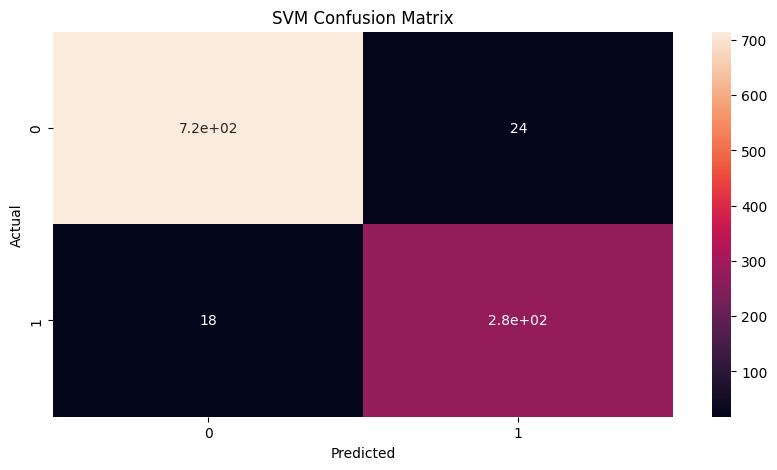

In [19]:
plt.figure(figsize=(10,5))
sns.heatmap(confusion_matrix(y_test, p1),annot = True)
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")



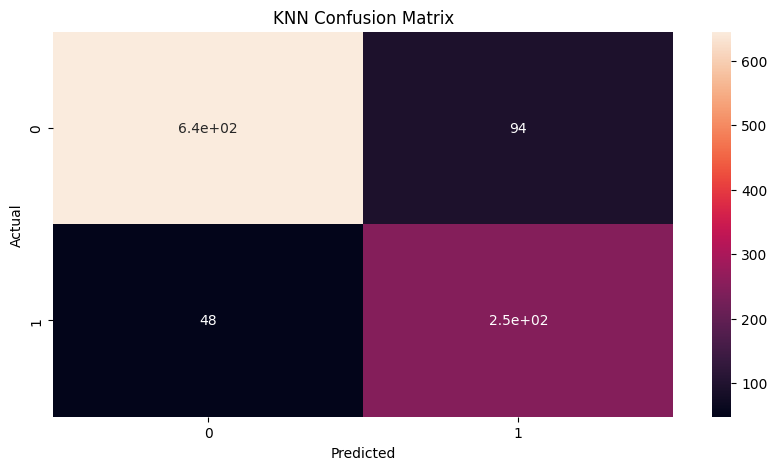

In [20]:
plt.figure(figsize=(10,5))
sns.heatmap(confusion_matrix(y_test, p2),annot = True)
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()